In [17]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import rasterize
import rasterio
import numpy as np
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape


region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
# === 1. 路径 ===
region = 'Severn_20210613'
# shp_path = f"H:\ICESat-2\DTFI_display\{region}.shp"
# ref_tif  = f"H:\ICESat-2\DTFI_display\{region}.tif"
# out_tif  = f"H:\ICESat-2\DTFI_display\{region}_id.tif"
shp_path ='H:\ICESat-2\DTFI_display\OTHER\S2_YC_.shp'
ref_tif = 'H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif'
out_tif  = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id.tif"

# =========================Severn_S2_20220812.tif
# 输入输出路径
# =========================
input_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
output_shp = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.shp"

input_tif = f"H:\ICESat-2\DTFI_display\Severn_S2_20220812.tif"
output_shp = f"H:\ICESat-2\DTFI_display\Severn_S2_20220812.shp"

# =========================
# 读取第5波段（NDWI）
# =========================
# =========================
with rasterio.open(input_tif) as src:
    
    ndwi = src.read(6)   # 第5波段
    transform = src.transform
    crs = src.crs

# =========================
# 二分类
# NDWI < 0.1 -> 1
# NDWI >=0.1 -> 0
# =========================
binary = np.where(ndwi > 0.2, 1, 0).astype(np.uint8)

# 如果有nodata
binary[np.isnan(ndwi)] = 255

# =========================
# 栅格转polygon
# =========================
results = []

for geom, value in shapes(binary, transform=transform):

    # 跳过nodata
    if value == 255:
        continue

    results.append({
        "geometry": shape(geom),
        "value": int(value)
    })

# =========================
# 转为GeoDataFrame
# =========================
gdf = gpd.GeoDataFrame(results, crs=crs)

# =========================
# 保存shp
# =========================
gdf.to_file(output_shp)

print("完成！")
print(gdf.head())

完成！
                                            geometry  value
0  POLYGON ((505950 5693460, 505950 5693430, 5060...      0
1  POLYGON ((506160 5693460, 506160 5693430, 5061...      0
2  POLYGON ((507180 5693430, 507210 5693430, 5072...      0
3  POLYGON ((506340 5693370, 506340 5693340, 5063...      0
4  POLYGON ((491550 5692140, 491610 5692140, 4916...      1


In [21]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import rasterize

# region = 'Wash_20230915_L8'
# === 1. 路径 ===
# input_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
# output_shp = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.shp"

shp_path =  f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_.shp"
ref_tif  = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
out_tif  = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id_.tif"

# === 2. 读取 shp ===
gdf = gpd.read_file(shp_path)

# 检查字段
print("字段列表:", gdf.columns)

# === 3. 打开参考影像 ===
with rasterio.open(ref_tif) as src:
    transform = src.transform
    out_shape = (src.height, src.width)
    crs = src.crs

# === 4. CRS 对齐 ===
if gdf.crs != crs:
    gdf = gdf.to_crs(crs)

# === 5. 构建 (geometry, id) ===
# ⚠️ 关键：用 id 字段赋值
shapes = [(geom, int(value)) for geom, value in zip(gdf.geometry, gdf['value'])]

# === 6. 栅格化 ===
raster = rasterize(
    shapes,
    out_shape=out_shape,
    transform=transform,
    fill=0,           # 背景为0
    dtype='int32'     # 用 int，避免 id 截断
)

# === 7. 写出 tif ===
with rasterio.open(
    out_tif,
    'w',
    driver='GTiff',
    height=out_shape[0],
    width=out_shape[1],
    count=1,
    dtype='int32',
    crs=crs,
    transform=transform,
) as dst:
    dst.write(raster, 1)

print("按 id 栅格化完成:", out_tif)

字段列表: Index(['value', 'geometry'], dtype='object')
按 id 栅格化完成: H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id_.tif


gt len = 3647705
正样本: 1318627
负样本: 2329078
AUC = 0.9806
NDWI AUC = 0.9931


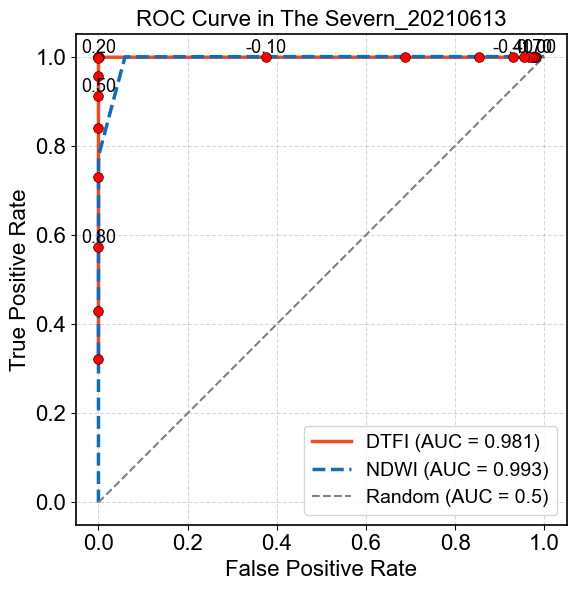

In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 路径
# =========================
region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
region_list = ['Morecambe_20250402_L8', 'Severn_20210721_L8', 'Solway_20240906_L8', 'Thames_20220421_L8', 'wash_20231125_L8']
name = 'The Severn_20210613'
# region = 'Severn_20210613'
region = 'Wash_20230915_L8'
dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id.tif"


# dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
# gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_id.tif"
region = 'Wash_20230915_L8'
dtfi_tif = f"H:\ICESat-2\DTFI_display\{region}.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\{region}_id.tif"
# =========================
# 2. 读取 DTFI
# =========================
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)   # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")
if ndwi.shape != gt.shape:
    raise ValueError("ndwi 与 GT 尺寸不一致，请确保使用同一参考栅格生成")

ndwi = ndwi.flatten()
dtfi = dtfi.flatten()
gt = gt.flatten()

valid_dtfi = ~np.isnan(dtfi)
valid_ndwi = ~np.isnan(ndwi)

if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

# GT 只保留 0 / 1
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt & valid_ndwi

dtfi = dtfi[mask]
ndwi = ndwi[mask]
gt = gt[mask]

print('gt len =', len(gt))

n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}")
print(f"负样本: {n_neg}")

if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

tpr_list = []
fpr_list = []
acc_list = []
tpr_ndwi_list = []
fpr_ndwi_list = []
acc_ndwi_list = []

thresholds = [-1, -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]


for th in thresholds:

    pred = (dtfi >= th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
    ACC = (TP + TN)/(TP + FP + TN + FN)

    tpr_list.append(TPR)
    fpr_list.append(FPR)
    acc_list.append(ACC)

thresholds = np.arange(-1, 1, 0.1)

for th in thresholds:

    pred = (ndwi < th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
    ACC = (TP + TN)/(TP + FP + TN + FN)
    
    acc_ndwi_list.append(ACC)
    tpr_ndwi_list.append(TPR)
    fpr_ndwi_list.append(FPR)

roc_auc = auc(fpr_list, tpr_list)
roc_auc_ndwi = auc(fpr_ndwi_list, tpr_ndwi_list)

print(f"AUC = {roc_auc:.4f}")
print(f"NDWI AUC = {roc_auc_ndwi:.4f}")

# 全局字体设置
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(fpr_list, tpr_list, lw=2.5, color = "#EB4E23FF", label=f'DTFI (AUC = {roc_auc:.3f})')
ax.plot(fpr_ndwi_list, tpr_ndwi_list, lw=2.5, linestyle='--',color = "#116DB9FF", label=f'NDWI (AUC = {roc_auc_ndwi:.3f})')

# ROC 点
ax.scatter(
    fpr_list,
    tpr_list,
    color='red',
    s=50,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)

# ax.scatter(
#     fpr_ndwi_list,
#     tpr_ndwi_list,
#     color='yellow',
#     s=50,
#     edgecolor='black',
#     linewidth=0.4,
#     zorder=3
# )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1.5,
    label='Random (AUC = 0.5)'
)

step = 3

# thresholds = np.arange(-1, 1, 0.1)
for i in range(0, len(thresholds), step):

    ax.text(
        fpr_list[i],
        tpr_list[i],
        f"{thresholds[i]:.2f}",
        fontsize=13,
        ha='center',
        va='bottom'
    )

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.2)

ax.set_title(
    f"ROC Curve in {name}",
    fontsize=16
)

ax.tick_params(
    axis='both',
    labelsize=16
)
ax.set_xlabel(
    "False Positive Rate",
    fontsize=16
)

ax.set_ylabel( "True Positive Rate", fontsize=16)

ax.grid(
    alpha=0.3,
    linestyle='--',
    color='gray'
)
ax.set_aspect('equal')

ax.legend(
    loc='lower right',
    fontsize=14
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()

plt.show()

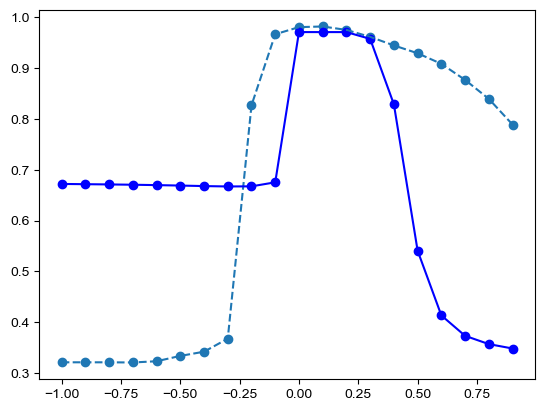

In [36]:

plt.plot(thresholds, acc_ndwi_list, linestyle='--')
plt.scatter(thresholds, acc_ndwi_list)
plt.plot(thresholds, acc_list, color = 'blue')
plt.scatter(thresholds, acc_list, color = 'blue')

Morecambe_20250402_L8
DTFI AUC = 0.9491
NDWI AUC = 0.9918
Severn_20210721_L8
DTFI AUC = 0.9289
NDWI AUC = 0.9921
Solway_20240906_L8
DTFI AUC = 0.9640
NDWI AUC = 0.9960
Thames_20220421_L8
DTFI AUC = 0.9481
NDWI AUC = 0.9889
Wash_20230915_L8
DTFI AUC = 0.9575
NDWI AUC = 0.9911


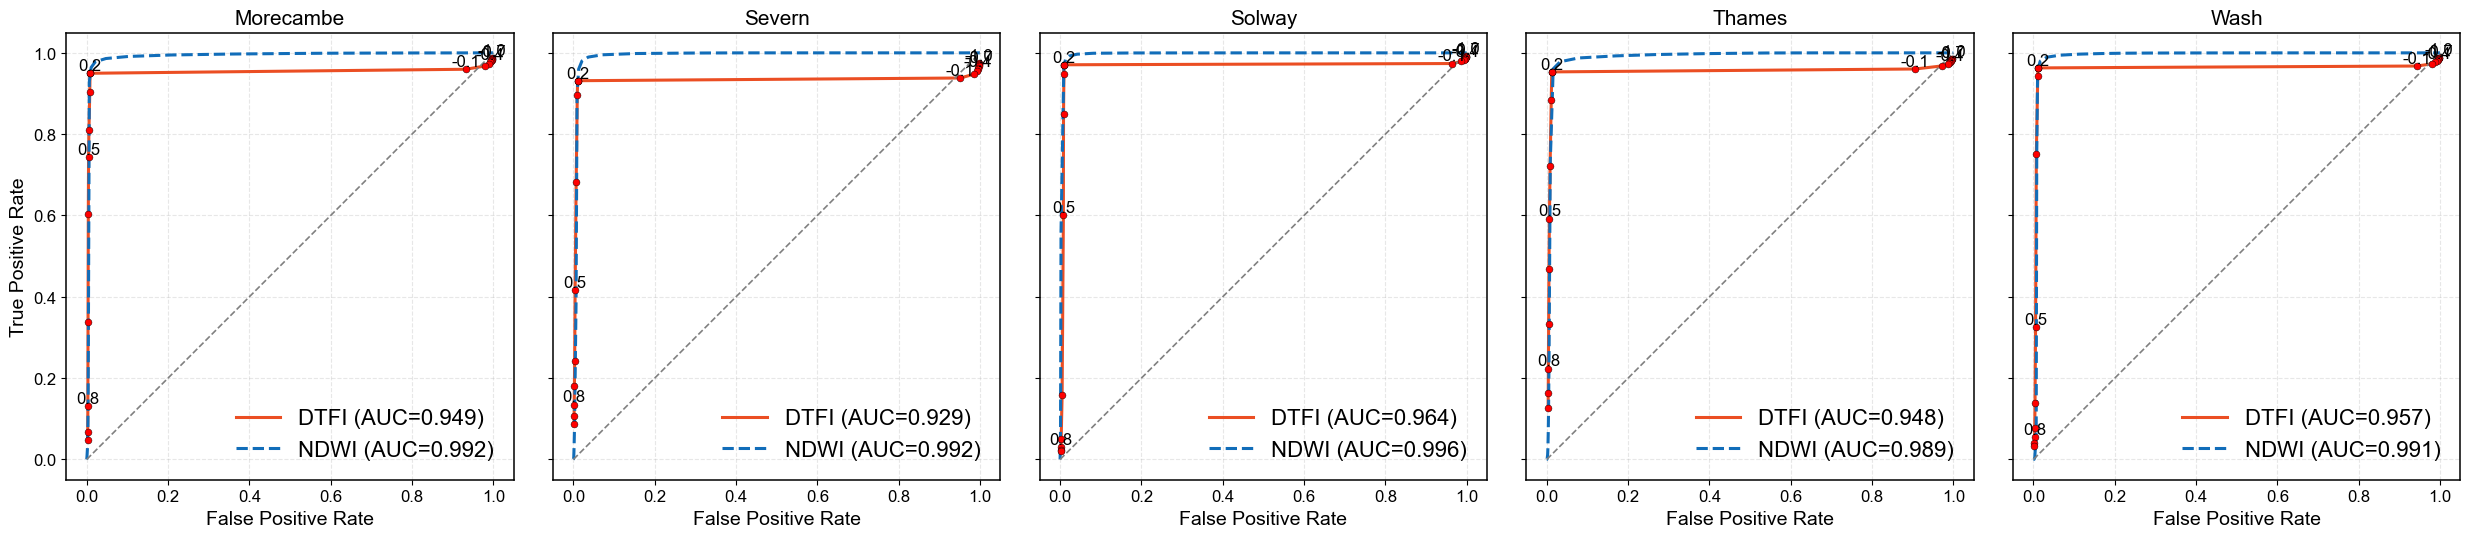

In [15]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 区域列表
# =========================
region_list = [
    'Morecambe_20250402_L8',
    'Severn_20210721_L8',
    'Solway_20240906_L8',
    'Thames_20220421_L8',
    'Wash_20230915_L8'
]

# =========================
# 2. 全局绘图设置
# =========================
plt.rcParams['font.family'] = 'Arial'

fig, axes = plt.subplots(
    1, 5,
    figsize=(25, 5),
    sharey=True   # 共享y轴
)

# =========================
# 3. 遍历区域
# =========================
for idx, region in enumerate(region_list):

    ax = axes[idx]

    # 名称显示
    name = region.split('_')[0]

    # 路径
    dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
    gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"

    # =========================
    # 读取 DTFI
    # =========================
    with rasterio.open(dtfi_tif) as src:
        dtfi = src.read(5).astype(float)
        dtfi_nodata = src.nodata

    # =========================
    # 读取 NDWI
    # =========================
    with rasterio.open(dtfi_tif) as src:
        ndwi = src.read(6).astype(float)
        ndwi_nodata = src.nodata

    # =========================
    # 读取 GT
    # =========================
    with rasterio.open(gt_tif) as src:
        gt = src.read(1).astype(int)
        gt_nodata = src.nodata

    # 检查尺寸
    if dtfi.shape != gt.shape:
        raise ValueError(f"{region}: DTFI 与 GT 尺寸不一致")

    if ndwi.shape != gt.shape:
        raise ValueError(f"{region}: NDWI 与 GT 尺寸不一致")

    # 展平
    dtfi = dtfi.flatten()
    ndwi = ndwi.flatten()
    gt = gt.flatten()

    # 有效值掩膜
    valid_dtfi = ~np.isnan(dtfi)
    valid_ndwi = ~np.isnan(ndwi)

    if dtfi_nodata is not None:
        valid_dtfi &= (dtfi != dtfi_nodata)

    if ndwi_nodata is not None:
        valid_ndwi &= (ndwi != ndwi_nodata)

    # GT 只保留 0 / 1
    valid_gt = (gt == 0) | (gt == 1)

    # 最终 mask
    mask = valid_dtfi & valid_ndwi & valid_gt

    dtfi = dtfi[mask]
    ndwi = ndwi[mask]
    gt = gt[mask]

    # =========================
    # ROC 计算
    # =========================
    # thresholds = np.arange(-1, 1, 0.1)
    thresholds = [-1, -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

    tpr_list = []
    fpr_list = []

    tpr_ndwi_list = []
    fpr_ndwi_list = []

    # ---------- DTFI ----------
    for th in thresholds:

        pred = (dtfi >= th).astype(int)

        TP = np.sum((pred == 1) & (gt == 1))
        FP = np.sum((pred == 1) & (gt == 0))
        TN = np.sum((pred == 0) & (gt == 0))
        FN = np.sum((pred == 0) & (gt == 1))

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

        tpr_list.append(TPR)
        fpr_list.append(FPR)

    # ---------- NDWI ----------
    for th in thresholds:

        pred = (ndwi < th).astype(int)

        TP = np.sum((pred == 1) & (gt == 1))
        FP = np.sum((pred == 1) & (gt == 0))
        TN = np.sum((pred == 0) & (gt == 0))
        FN = np.sum((pred == 0) & (gt == 1))

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

        tpr_ndwi_list.append(TPR)
        fpr_ndwi_list.append(FPR)

    # =========================
    # AUC
    # =========================
    roc_auc = auc(fpr_list, tpr_list)
    roc_auc_ndwi = auc(fpr_ndwi_list, tpr_ndwi_list)
    
    

    print(f"{region}")
    print(f"DTFI AUC = {roc_auc:.4f}")
    print(f"NDWI AUC = {roc_auc_ndwi:.4f}")

    # =========================
    # 绘图
    # =========================
    ax.plot(
        fpr_list,
        tpr_list,
        lw=2.2,
        color="#EB4E23FF",
        label=f'DTFI (AUC={roc_auc:.3f})'
    )

    ax.plot(
        fpr_ndwi_list,
        tpr_ndwi_list,
        lw=2.2,
        linestyle='--',
        color="#116DB9FF",
        label=f'NDWI (AUC={roc_auc_ndwi:.3f})'
    )

    # ROC 点
    ax.scatter(
        fpr_list,
        tpr_list,
        color='red',
        s=25,
        edgecolor='black',
        linewidth=0.3,
        zorder=3
    )

    # 随机线
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray',
        linewidth=1.2
    )

    # 阈值标注
    step = 3

    for i in range(0, len(thresholds), step):

        ax.text(
            fpr_list[i],
            tpr_list[i],
            f"{thresholds[i]:.1f}",
            fontsize=12,
            ha='center',
            va='bottom'
        )

    # 坐标轴设置
    ax.set_title(
        name,
        fontsize=15
    )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect('equal')

    ax.grid(
        alpha=0.3,
        linestyle='--'
    )

    ax.tick_params(
        axis='both',
        labelsize=12
    )

    # 只显示第一个子图的 y 轴
    if idx == 0:
        ax.set_ylabel(
            "True Positive Rate",
            fontsize=14
        )
    else:
        ax.set_ylabel("")
        ax.tick_params(labelleft=False)

    # 所有子图都显示 x 轴
    ax.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    # 边框
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.1)

    # 图例
    ax.legend(
        loc='lower right',
        fontsize=16,
        frameon=False
    )

# =========================
# 布局
# =========================
plt.tight_layout()

plt.show()

In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 区域列表
# =========================
region_list = [
    'Morecambe_20250402_L8',
    'Severn_20210721_L8',
    'Solway_20240906_L8',
    'Thames_20220421_L8',
    'Wash_20230915_L8'
]

# =========================
# 2. threshold
# =========================
thresholds = [
    -1, -0.9, -0.8, -0.7, -0.6,
    -0.5, -0.4, -0.3, -0.2, -0.1,
     0,  0.1,  0.2,  0.3,  0.4,
     0.5, 0.6, 0.7, 0.8, 0.9, 1
]

# =========================
# 3. 全局绘图设置
# =========================
plt.rcParams['font.family'] = 'Arial'

fig, axes = plt.subplots(
    2, 5,
    figsize=(25, 10),
    sharex=False,
    sharey=False
)

# =========================
# 4. 遍历区域
# =========================
for idx, region in enumerate(region_list):

    # =========================
    # 第一排：ROC
    # 第二排：ACC
    # =========================
    ax_roc = axes[0, idx]
    ax_acc = axes[1, idx]

    # =========================
    # 名称
    # =========================
    name = region.split('_')[0]

    # =========================
    # 文件路径
    # =========================
    dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
    gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"

    # =========================
    # 读取 DTFI
    # =========================
    with rasterio.open(dtfi_tif) as src:

        dtfi = src.read(5).astype(float)
        dtfi_nodata = src.nodata

    # =========================
    # 读取 NDWI
    # =========================
    with rasterio.open(dtfi_tif) as src:

        ndwi = src.read(6).astype(float)
        ndwi_nodata = src.nodata

    # =========================
    # 读取 GT
    # =========================
    with rasterio.open(gt_tif) as src:

        gt = src.read(1).astype(int)

    # =========================
    # 检查尺寸
    # =========================
    if dtfi.shape != gt.shape:
        raise ValueError(f"{region}: DTFI 与 GT 尺寸不一致")

    if ndwi.shape != gt.shape:
        raise ValueError(f"{region}: NDWI 与 GT 尺寸不一致")

    # =========================
    # 展平
    # =========================
    dtfi = dtfi.flatten()
    ndwi = ndwi.flatten()
    gt = gt.flatten()

    # =========================
    # mask
    # =========================
    valid_dtfi = ~np.isnan(dtfi)
    valid_ndwi = ~np.isnan(ndwi)

    if dtfi_nodata is not None:
        valid_dtfi &= (dtfi != dtfi_nodata)

    if ndwi_nodata is not None:
        valid_ndwi &= (ndwi != ndwi_nodata)

    valid_gt = (gt == 0) | (gt == 1)

    mask = valid_dtfi & valid_ndwi & valid_gt

    dtfi = dtfi[mask]
    ndwi = ndwi[mask]
    gt = gt[mask]

    # =========================
    # ROC + ACC
    # =========================
    tpr_list = []
    fpr_list = []
    acc_list = []

    tpr_ndwi_list = []
    fpr_ndwi_list = []
    acc_ndwi_list = []

    # =========================
    # DTFI
    # =========================
    for th in thresholds:

        pred = (dtfi >= th).astype(int)

        TP = np.sum((pred == 1) & (gt == 1))
        FP = np.sum((pred == 1) & (gt == 0))
        TN = np.sum((pred == 0) & (gt == 0))
        FN = np.sum((pred == 0) & (gt == 1))

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
        ACC = (TP + TN) / (TP + FP + TN + FN)

        tpr_list.append(TPR)
        fpr_list.append(FPR)
        acc_list.append(ACC)

    # =========================
    # NDWI
    # =========================
    for th in thresholds:

        pred = (ndwi < th).astype(int)

        TP = np.sum((pred == 1) & (gt == 1))
        FP = np.sum((pred == 1) & (gt == 0))
        TN = np.sum((pred == 0) & (gt == 0))
        FN = np.sum((pred == 0) & (gt == 1))

        TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
        ACC = (TP + TN) / (TP + FP + TN + FN)

        tpr_ndwi_list.append(TPR)
        fpr_ndwi_list.append(FPR)
        acc_ndwi_list.append(ACC)

    # =========================
    # AUC
    # =========================
    roc_auc = auc(fpr_list, tpr_list)
    roc_auc_ndwi = auc(fpr_ndwi_list, tpr_ndwi_list)

    print(f"{region}")
    print(f"DTFI AUC = {roc_auc:.4f}")
    print(f"NDWI AUC = {roc_auc_ndwi:.4f}")

    # =========================================================
    # 第一排：ROC
    # =========================================================
    ax_roc.plot(
        fpr_list,
        tpr_list,
        lw=2.2,
        color="#EB4E23FF",
        label=f'DTFI (AUC={roc_auc:.3f})'
    )

    ax_roc.plot(
        fpr_ndwi_list,
        tpr_ndwi_list,
        lw=2.2,
        linestyle='--',
        color="#116DB9FF",
        label=f'NDWI (AUC={roc_auc_ndwi:.3f})'
    )
    
    ax_roc.scatter(
        fpr_list,
        tpr_list,
        color='red',
        s=25,
        edgecolor='black',
        linewidth=0.3,
        zorder=3
    )

    ax_roc.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray',
        linewidth=1.2
    )

    # threshold 标注
    step = 3

    for i in range(0, len(thresholds), step):

        ax_roc.text(
            fpr_list[i],
            tpr_list[i],
            f"{thresholds[i]:.1f}",
            fontsize=10,
            ha='center',
            va='bottom'
        )

    # ROC 坐标轴
    ax_roc.set_title(
        name,
        fontsize=15
    )

    ax_roc.set_xlim(-0.05, 1.05)
    ax_roc.set_ylim(-0.05, 1.05)

    ax_roc.set_aspect('equal')

    ax_roc.grid(
        alpha=0.3,
        linestyle='--'
    )

    ax_roc.tick_params(
        axis='both',
        labelsize=12
    )

    if idx == 0:

        ax_roc.set_ylabel(
            "True Positive Rate",
            fontsize=14
        )

    else:

        ax_roc.set_ylabel("")
        ax_roc.tick_params(labelleft=False)

    ax_roc.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    # 图例
    ax_roc.legend(
        loc='lower right',
        fontsize=11,
        frameon=False
    )

    ax_acc.plot(
        thresholds,
        acc_list,
        lw=2.2,
        color="#EB4E23FF",
        label='DTFI'
    )

    ax_acc.plot(
        thresholds,
        acc_ndwi_list,
        lw=2.2,
        linestyle='--',
        color="#116DB9FF",
        label='NDWI'
    )

    # 最大 ACC 点
    best_dtfi = np.argmax(acc_list)
    best_ndwi = np.argmax(acc_ndwi_list)

    ax_acc.scatter(
        thresholds[best_dtfi],
        acc_list[best_dtfi],
        color="#EB4E23FF",
        s=40,
        edgecolor='black',
        zorder=3
    )

    ax_acc.scatter(
        thresholds[best_ndwi],
        acc_ndwi_list[best_ndwi],
        color="#116DB9FF",
        s=40,
        edgecolor='black',
        zorder=3
    )

    ax_acc.text(
        thresholds[best_dtfi],
        acc_list[best_dtfi],
        f"{thresholds[best_dtfi]:.1f}",
        fontsize=10,
        ha='center',
        va='bottom'
    )

    ax_acc.text(
        thresholds[best_ndwi],
        acc_ndwi_list[best_ndwi],
        f"{thresholds[best_ndwi]:.1f}",
        fontsize=10,
        ha='center',
        va='bottom'
    )

    # ACC 坐标轴
    ax_acc.set_xlim(-1.05, 1.05)
    ax_acc.set_ylim(0.4, 1.02)

    ax_acc.grid(
        alpha=0.3,
        linestyle='--'
    )

    ax_acc.tick_params(
        axis='both',
        labelsize=12
    )

    if idx == 0:

        ax_acc.set_ylabel(
            "Overall Accuracy",
            fontsize=14
        )

    else:

        ax_acc.set_ylabel("")
        ax_acc.tick_params(labelleft=False)

    ax_acc.set_xlabel(
        "Threshold",
        fontsize=14
    )

    ax_acc.legend(
        loc='lower right',
        fontsize=11,
        frameon=False
    )

    for spine in ax_roc.spines.values():

        spine.set_color('black')
        spine.set_linewidth(1.1)

    for spine in ax_acc.spines.values():

        spine.set_color('black')
        spine.set_linewidth(1.1)

plt.tight_layout()

plt.show()


Morecambe_20250402_L8
Positive samples = 298120
Negative samples = 234174
DTFI AUC = 0.9490
NDWI AUC = 0.9921

Severn_20210721_L8
Positive samples = 149655
Negative samples = 656449
DTFI AUC = 0.9282
NDWI AUC = 0.9923

Solway_20240906_L8
Positive samples = 154941
Negative samples = 380657
DTFI AUC = 0.9643
NDWI AUC = 0.9963

Thames_20220421_L8
Positive samples = 198419
Negative samples = 341339
DTFI AUC = 0.9497
NDWI AUC = 0.9895

Wash_20230915_L8
Positive samples = 206411
Negative samples = 97541
DTFI AUC = 0.9584
NDWI AUC = 0.9912


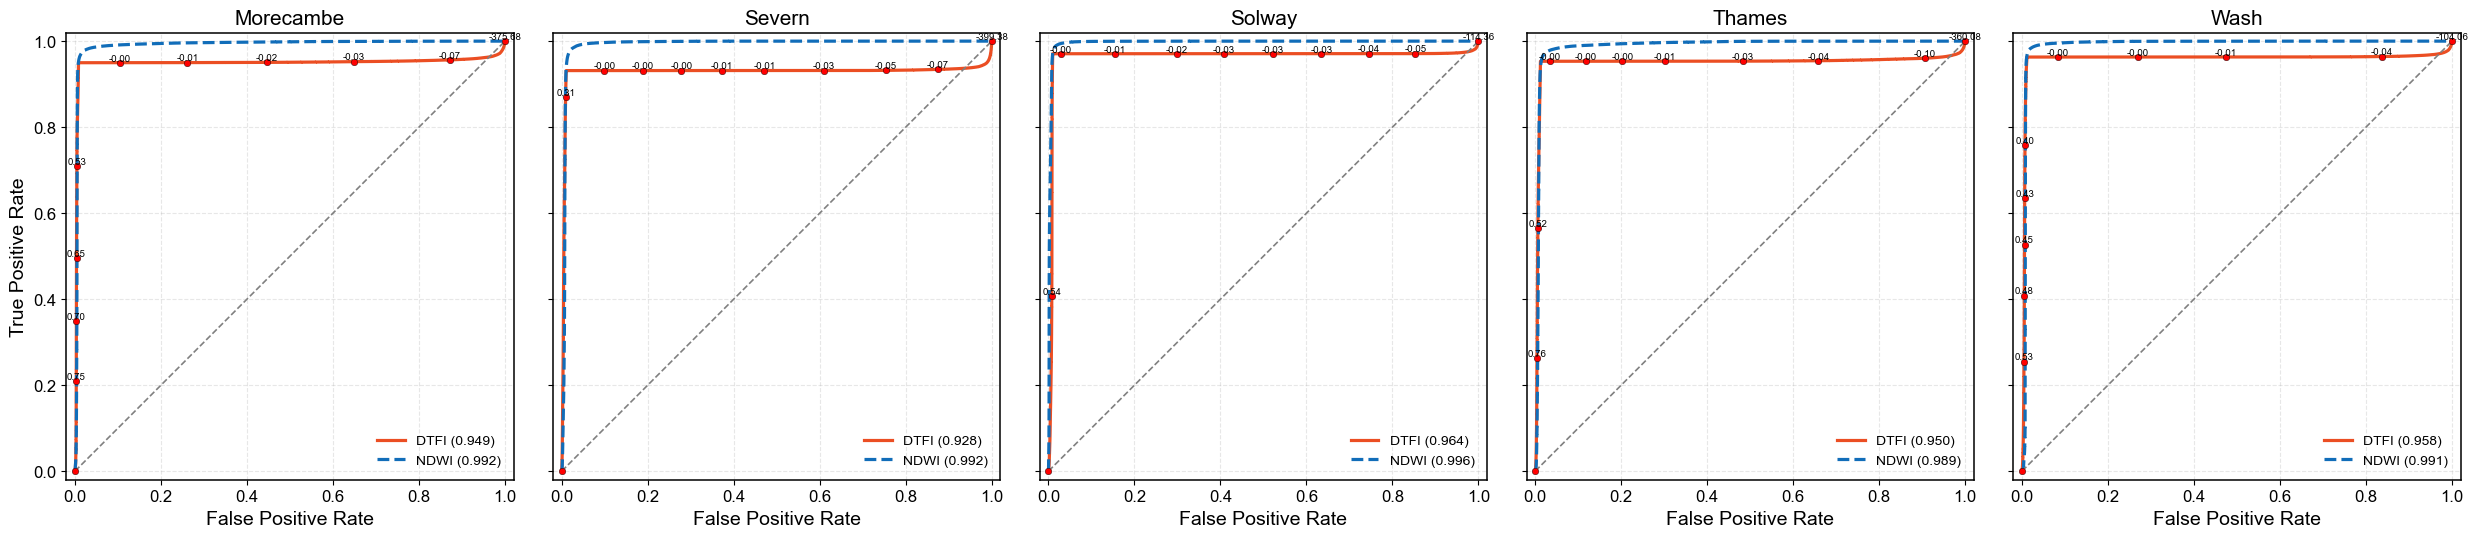

In [7]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# =========================
# 1. 区域列表
# =========================
region_list = [
    'Morecambe_20250402_L8',
    'Severn_20210721_L8',
    'Solway_20240906_L8',
    'Thames_20220421_L8',
    'Wash_20230915_L8'
]

# =========================
# 2. 全局绘图设置
# =========================
plt.rcParams['font.family'] = 'Arial'

fig, axes = plt.subplots(
    1, 5,
    figsize=(25, 5),
    sharey=True
)

# =========================
# 3. 遍历区域
# =========================
for idx, region in enumerate(region_list):

    ax = axes[idx]

    # =========================
    # 名称显示
    # =========================
    name = region.split('_')[0]

    # =========================
    # 文件路径
    # =========================
    dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
    gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"

    # =========================
    # 读取 DTFI
    # Band 5
    # =========================
    with rasterio.open(dtfi_tif) as src:

        dtfi = src.read(5).astype(float)
        dtfi_nodata = src.nodata

    # =========================
    # 读取 NDWI
    # Band 6
    # =========================
    with rasterio.open(dtfi_tif) as src:

        ndwi = src.read(6).astype(float)
        ndwi_nodata = src.nodata

    # =========================
    # 读取 GT
    # =========================
    with rasterio.open(gt_tif) as src:

        gt = src.read(1).astype(int)

    # =========================
    # 检查尺寸
    # =========================
    if dtfi.shape != gt.shape:
        raise ValueError(f"{region}: DTFI 与 GT 尺寸不一致")

    if ndwi.shape != gt.shape:
        raise ValueError(f"{region}: NDWI 与 GT 尺寸不一致")

    # =========================
    # 展平
    # =========================
    dtfi = dtfi.flatten()
    ndwi = ndwi.flatten()
    gt = gt.flatten()

    # =========================
    # 有效值 mask
    # =========================
    valid_dtfi = ~np.isnan(dtfi)
    valid_ndwi = ~np.isnan(ndwi)

    if dtfi_nodata is not None:
        valid_dtfi &= (dtfi != dtfi_nodata)

    if ndwi_nodata is not None:
        valid_ndwi &= (ndwi != ndwi_nodata)

    # GT 只保留 0 / 1
    valid_gt = (gt == 0) | (gt == 1)

    # 最终 mask
    mask = valid_dtfi & valid_ndwi & valid_gt

    dtfi = dtfi[mask]
    ndwi = ndwi[mask]
    gt = gt[mask]

    # =========================
    # 样本统计
    # =========================
    n_pos = np.sum(gt == 1)
    n_neg = np.sum(gt == 0)

    print(f"\n{region}")
    print(f"Positive samples = {n_pos}")
    print(f"Negative samples = {n_neg}")

    # =========================
    # ROC - DTFI
    # score 越大越偏向 positive
    # =========================
    fpr_dtfi, tpr_dtfi, thresholds_dtfi = roc_curve(
        gt,
        dtfi
    )

    auc_dtfi = auc(
        fpr_dtfi,
        tpr_dtfi
    )

    # =========================
    # ROC - NDWI
    # 原逻辑：
    # ndwi < threshold → positive
    #
    # sklearn 默认：
    # score 越大越偏向 positive
    #
    # 因此这里使用 -ndwi
    # =========================
    fpr_ndwi, tpr_ndwi, thresholds_ndwi = roc_curve(
        gt,
        -ndwi
    )

    auc_ndwi = auc(
        fpr_ndwi,
        tpr_ndwi
    )

    print(f"DTFI AUC = {auc_dtfi:.4f}")
    print(f"NDWI AUC = {auc_ndwi:.4f}")

    # =========================
    # 绘制 ROC 曲线
    # =========================
    ax.plot(
        fpr_dtfi,
        tpr_dtfi,
        lw=2.3,
        color="#EB4E23FF",
        label=f'DTFI ({auc_dtfi:.3f})'
    )

    ax.plot(
        fpr_ndwi,
        tpr_ndwi,
        lw=2.3,
        linestyle='--',
        color="#116DB9FF",
        label=f'NDWI ({auc_ndwi:.3f})'
    )

    # =========================
    # DTFI ROC 点
    # =========================
    step = max(1, len(fpr_dtfi) // 10)

    ax.scatter(
        fpr_dtfi[::step],
        tpr_dtfi[::step],
        color='red',
        s=22,
        edgecolor='black',
        linewidth=0.3,
        zorder=3
    )

    # =========================
    # threshold 标注
    # =========================
    for i in range(0, len(thresholds_dtfi), step):

        # 跳过 inf
        if np.isinf(thresholds_dtfi[i]):
            continue

        ax.text(
            fpr_dtfi[i],
            tpr_dtfi[i],
            f"{thresholds_dtfi[i]:.2f}",
            fontsize=7,
            ha='center',
            va='bottom'
        )

    # =========================
    # 随机分类线
    # =========================
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray',
        linewidth=1.2
    )

    # =========================
    # 坐标轴设置
    # =========================
    ax.set_title(
        name,
        fontsize=15
    )

    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)

    ax.set_aspect('equal')

    ax.grid(
        alpha=0.3,
        linestyle='--'
    )

    ax.tick_params(
        axis='both',
        labelsize=12
    )

    # =========================
    # 只显示第一个 y 轴
    # =========================
    if idx == 0:

        ax.set_ylabel(
            "True Positive Rate",
            fontsize=14
        )

    else:

        ax.set_ylabel("")
        ax.tick_params(labelleft=False)

    # =========================
    # x 轴
    # =========================
    ax.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    # =========================
    # 边框
    # =========================
    for spine in ax.spines.values():

        spine.set_color('black')
        spine.set_linewidth(1.1)

    # =========================
    # 图例
    # =========================
    ax.legend(
        loc='lower right',
        fontsize=10,
        frameon=False
    )

# =========================
# 布局
# =========================
plt.tight_layout()

plt.show()


S2_HHK_20240907
Positive samples = 179575
Negative samples = 327998
DTFI AUC = 0.9938
NDWI AUC = 0.9990

S2_YC_20220408
Positive samples = 1318627
Negative samples = 2329078
DTFI AUC = 0.9987
NDWI AUC = 0.9993


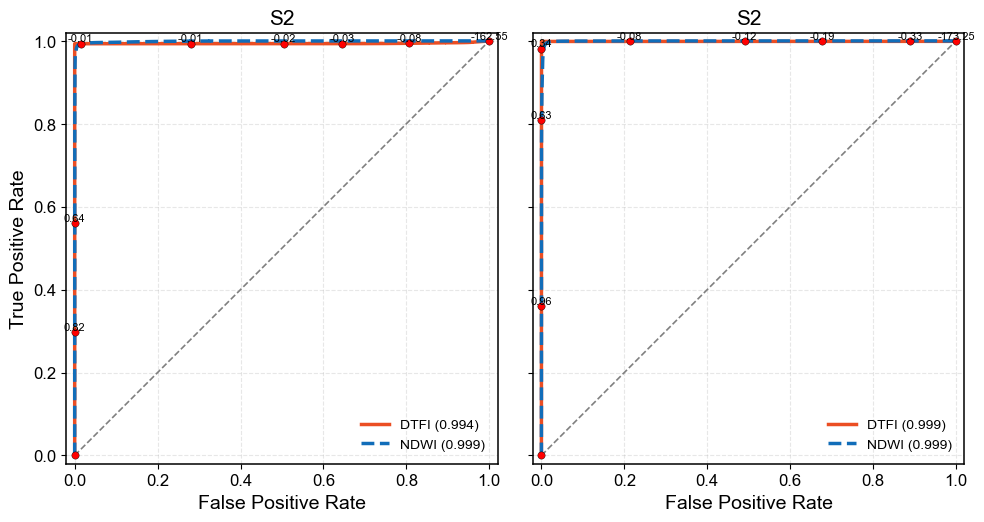

In [6]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# =========================
# 1. 区域列表
# =========================
region_list = [
    'Morecambe_20250402_L8',
    'Severn_20210721_L8',
    'Solway_20240906_L8',
    'Thames_20220421_L8',
    'Wash_20230915_L8'
]

region_list = ['S2_HHK_20240907', 'S2_YC_20220408']

# =========================
# 2. 全局字体
# =========================
plt.rcParams['font.family'] = 'Arial'

# =========================
# 3. 创建子图
# =========================
fig, axes = plt.subplots(
    1, len(region_list),
    figsize=(len(region_list)*5, 5),
    sharey=True
)

# =========================
# 4. 遍历区域
# =========================
for idx, region in enumerate(region_list):

    ax = axes[idx]

    # -------------------------
    # 区域名（用于标题）
    # -------------------------
    name = region.split('_')[0]

    # -------------------------
    # 文件路径
    # -------------------------
    dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\OTHER\\{region}.tif"
    gt_tif   = f"H:\\ICESat-2\\DTFI_display\\OTHER\\{region}_id.tif"

    # =========================
    # 读取 DTFI
    # Band 5
    # =========================
    with rasterio.open(dtfi_tif) as src:

        dtfi = src.read(6).astype(float)
        dtfi_nodata = src.nodata

    # =========================
    # 读取 NDWI
    # Band 6
    # =========================
    with rasterio.open(dtfi_tif) as src:

        ndwi = src.read(7).astype(float)
        ndwi_nodata = src.nodata

    # =========================
    # 读取 GT
    # =========================
    with rasterio.open(gt_tif) as src:

        gt = src.read(1).astype(int)
        gt_nodata = src.nodata

    # =========================
    # 检查尺寸
    # =========================
    if dtfi.shape != gt.shape:
        raise ValueError(f"{region}: DTFI 与 GT 尺寸不一致")

    if ndwi.shape != gt.shape:
        raise ValueError(f"{region}: NDWI 与 GT 尺寸不一致")

    # =========================
    # 展平
    # =========================
    dtfi = dtfi.flatten()
    ndwi = ndwi.flatten()
    gt = gt.flatten()

    # =========================
    # 有效值掩膜
    # =========================
    valid_dtfi = ~np.isnan(dtfi)
    valid_ndwi = ~np.isnan(ndwi)

    if dtfi_nodata is not None:
        valid_dtfi &= (dtfi != dtfi_nodata)

    if ndwi_nodata is not None:
        valid_ndwi &= (ndwi != ndwi_nodata)

    # GT 只保留 0 / 1
    valid_gt = (gt == 0) | (gt == 1)

    # 最终 mask
    mask = valid_dtfi & valid_ndwi & valid_gt

    dtfi = dtfi[mask]
    ndwi = ndwi[mask]
    gt = gt[mask]

    # =========================
    # 样本统计
    # =========================
    n_pos = np.sum(gt == 1)
    n_neg = np.sum(gt == 0)

    print(f"\n{region}")
    print(f"Positive samples = {n_pos}")
    print(f"Negative samples = {n_neg}")

    # =========================
    # ROC - DTFI
    # =========================
    fpr_dtfi, tpr_dtfi, th_dtfi = roc_curve(
        gt,
        dtfi
    )

    auc_dtfi = auc(
        fpr_dtfi,
        tpr_dtfi
    )

    # =========================
    # ROC - NDWI
    # 注意：
    # 原逻辑是 ndwi < threshold
    # sklearn 默认 score 越大越偏向 positive
    # 所以这里使用 -ndwi
    # =========================
    fpr_ndwi, tpr_ndwi, th_ndwi = roc_curve(
        gt,
        -ndwi
    )

    auc_ndwi = auc(
        fpr_ndwi,
        tpr_ndwi
    )

    print(f"DTFI AUC = {auc_dtfi:.4f}")
    print(f"NDWI AUC = {auc_ndwi:.4f}")

    # =========================
    # 绘制 ROC 曲线
    # =========================
    ax.plot(
        fpr_dtfi,
        tpr_dtfi,
        lw=2.5,
        color="#EB4E23FF",
        label=f'DTFI ({auc_dtfi:.3f})'
    )

    ax.plot(
        fpr_ndwi,
        tpr_ndwi,
        lw=2.5,
        linestyle='--',
        color="#116DB9FF",
        label=f'NDWI ({auc_ndwi:.3f})'
    )

    # =========================
    # 随机分类线
    # =========================
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray',
        linewidth=1.2
    )

    # =========================
    # DTFI ROC 点
    # =========================
    step = max(1, len(fpr_dtfi) // 8)

    ax.scatter(
        fpr_dtfi[::step],
        tpr_dtfi[::step],
        color='red',
        s=28,
        edgecolor='black',
        linewidth=0.3,
        zorder=3
    )

    # =========================
    # threshold 标注
    # =========================
    for i in range(0, len(th_dtfi), step):

        # sklearn 第一个 threshold 是 inf
        if np.isinf(th_dtfi[i]):
            continue

        ax.text(
            fpr_dtfi[i],
            tpr_dtfi[i],
            f"{th_dtfi[i]:.2f}",
            fontsize=8,
            ha='center',
            va='bottom'
        )

    # =========================
    # 坐标轴设置
    # =========================
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)

    ax.set_aspect('equal')

    ax.grid(
        alpha=0.3,
        linestyle='--'
    )

    ax.tick_params(
        axis='both',
        labelsize=12
    )

    # =========================
    # 标题
    # =========================
    ax.set_title(
        name,
        fontsize=15
    )

    # =========================
    # X轴
    # =========================
    ax.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    # =========================
    # 只有第一个显示Y轴
    # =========================
    if idx == 0:

        ax.set_ylabel(
            "True Positive Rate",
            fontsize=14
        )

    else:

        ax.set_ylabel("")
        ax.tick_params(labelleft=False)

    # =========================
    # 边框
    # =========================
    for spine in ax.spines.values():

        spine.set_color('black')
        spine.set_linewidth(1.1)

    # =========================
    # 图例
    # =========================
    ax.legend(
        loc='lower right',
        fontsize=10,
        frameon=False
    )

# =========================
# 布局
# =========================
plt.tight_layout()

# =========================
# 保存（可选）
# =========================
# plt.savefig(
#     r"H:\ICESat-2\ROC_5regions.png",
#     dpi=600,
#     bbox_inches='tight'
# )

plt.show()

TPR 0.35903843029983373
FPR 0.10307542494408446


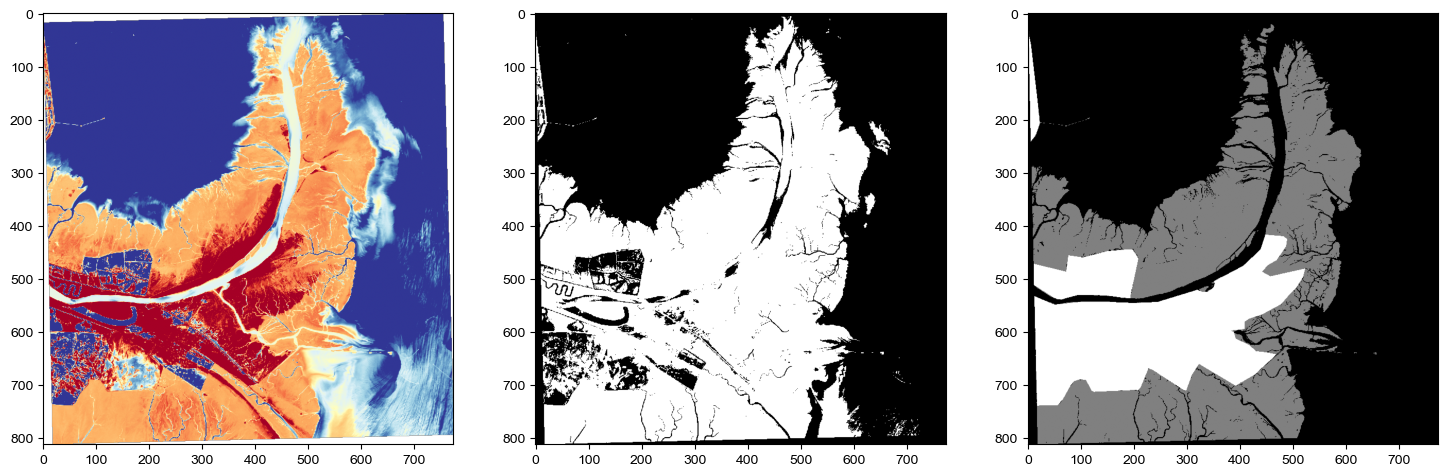

In [ ]:
# region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
# name = 'The Severn_20210613'
# # region = 'Severn_20210613'
# region = 'Wash20220811'
# dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_id.tif"

# dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform
with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform


fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# -------------------------
# Binary map
# -------------------------
axes[0].imshow(ndwi, vmin=-0.5, vmax=0.5, cmap='RdYlBu')

binary = np.where(ndwi < 0.1, 1, 0)
axes[1].imshow(binary,  cmap='gray')

axes[2].imshow(gt,  cmap='gray')
# plt.imshow(ndwi, vmin=-0.5, vmax=0.5, cmap='RdYlBu')
# plt.imshow(dtfi, vmin=-0.5, vmax=2, cmap='RdYlBu')
# plt.imshow(ndwi, vmin=-0.5, vmax=0, cmap='RdYlBu')
TP = np.sum((binary == 1) & (gt == 1))
FP = np.sum((binary == 1) & (gt == 0))
TN = np.sum((binary == 0) & (gt == 0))
FN = np.sum((binary == 0) & (gt == 1))
TPR = TP / (TP + FN)
FPR = FP / (FP + TN)
print('TPR',TPR)
print('FPR',FPR)

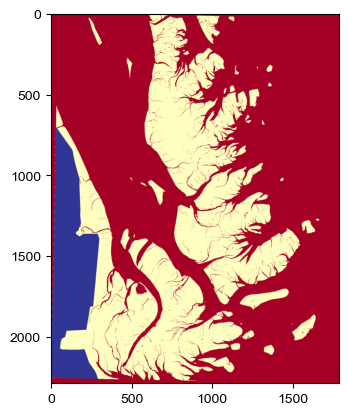

In [78]:
with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform
plt.imshow(gt, cmap='RdYlBu')

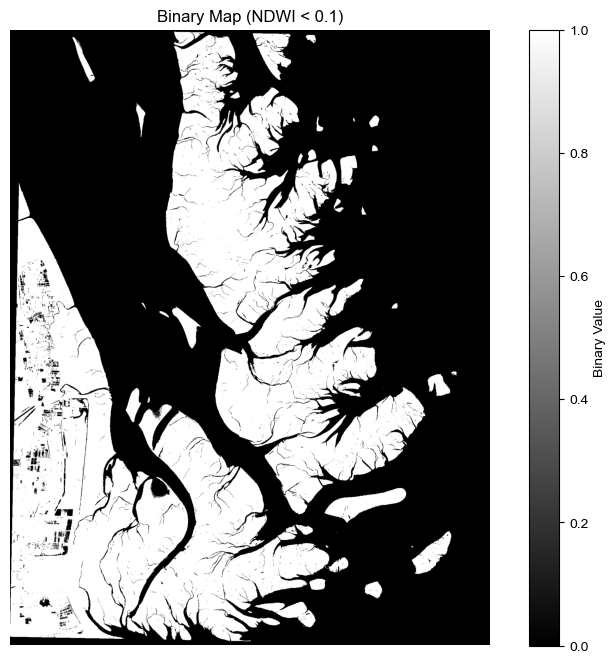

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 读取 NDWI
# =========================
with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(6).astype(float)
    ndwi_nodata = src.nodata

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

# =========================
# 处理 nodata
# =========================
if ndwi_nodata is not None:
    ndwi[ndwi == ndwi_nodata] = np.nan

binary = np.where(ndwi > 0, 1, 0)

# NaN 区域重新设为 NaN（避免显示）
# binary[np.isnan(ndwi)] = np.nan

# =========================
# 显示 Binary Map
# =========================
plt.figure(figsize=(10, 8))

im = plt.imshow(
    binary,
    cmap='gray',
    vmin=0,
    vmax=1
)

plt.colorbar(im, label='Binary Value')

plt.title('Binary Map (NDWI < 0.1)')
plt.axis('off')

plt.show()

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# =========================
# 读取 NDWI
# =========================
with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(6).astype(float)
    ndwi_nodata = src.nodata

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata


if ndwi_nodata is not None:
    ndwi[ndwi == ndwi_nodata] = np.nan

binary = np.where(ndwi > 0.2, 1, 0)

diff = np.zeros_like(gt)

# True Negative
diff[(binary == 0) & (gt == 0)] = 0

# False Positive
diff[(binary == 1) & (gt == 0)] = 1

# False Negative
diff[(binary == 0) & (gt == 1)] = 2

# True Positive
diff[(binary == 1) & (gt == 1)] = 3

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

# -------------------------
# Binary map
# -------------------------
axes[0].imshow(binary, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Binary Map')
axes[0].axis('off')

# -------------------------
# GT
# -------------------------
axes[1].imshow(gt, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Ground Truth')
axes[1].axis('off')

# -------------------------
# Difference map
# -------------------------
cmap = ListedColormap([
    'black',   # TN
    'red',     # FP
    'blue',    # FN
    'white'    # TP
])

im = axes[2].imshow(diff, cmap=cmap, vmin=0, vmax=3)

axes[2].set_title('Difference Map')
axes[2].axis('off')


# axes[3].imshow()

# colorbar
cbar = plt.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)

cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels([
    'TN',
    'FP',
    'FN',
    'TP'
])

plt.tight_layout()
plt.show()

TP = np.sum((binary == 1) & (gt == 1))
FP = np.sum((binary == 1) & (gt == 0))
TN = np.sum((binary == 0) & (gt == 0))
FN = np.sum((binary == 0) & (gt == 1))
TPR = TP / (TP + FN)
FPR = FP / (FP + TN)
print('TPR',TPR)
print('FPR',FPR)
print('TP =', TP)
print('FP =', FP)
print('TN =', TN)
print('FN =', FN)



print(thresholds)

print('acc:', (TP+TN)/(TP+FP+TN+FN))

In [91]:
FP / (FP + TN)


0.056172580663440504

In [ ]:
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)   # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform


with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

# =========================
# 4. 检查是否对齐
# =========================
if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")
if ndwi.shape != gt.shape:
    raise ValueError("ndwi 与 GT 尺寸不一致，请确保使用同一参考栅格生成")


ndwi = ndwi.flatten()
dtfi = dtfi.flatten()
gt = gt.flatten()

valid_dtfi = ~np.isnan(dtfi)
valid_ndwi = ~np.isnan(ndwi)

if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

# GT 只保留 0 / 1
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt & valid_ndwi

dtfi = dtfi[mask]
ndwi = ndwi[mask]
gt = gt[mask]

print('gt len =', len(gt))

n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}")
print(f"负样本: {n_neg}")

if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

thresholds = np.arange(-1, 1.01, 0.1)

tpr_list = []
fpr_list = []
tpr_ndwi_list = []
fpr_ndwi_list = []

# thresholds = [-0.5, 0, 0.5]

tpr_list = []
fpr_list = []

for th in thresholds:

    pred = (ndwi < th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)

    tpr_ndwi_list.append(TPR)
    fpr_ndwi_list.append(FPR)
    
for th in thresholds:

    pred = (dtfi > th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)

    tpr_list.append(TPR)
    fpr_list.append(FPR)


print(thresholds)
print(tpr_list)
print(fpr_list)

gt len = 3647705
正样本: 1318627
负样本: 2329078
[-1.0000000e+00 -9.5000000e-01 -9.0000000e-01 -8.5000000e-01
 -8.0000000e-01 -7.5000000e-01 -7.0000000e-01 -6.5000000e-01
 -6.0000000e-01 -5.5000000e-01 -5.0000000e-01 -4.5000000e-01
 -4.0000000e-01 -3.5000000e-01 -3.0000000e-01 -2.5000000e-01
 -2.0000000e-01 -1.5000000e-01 -1.0000000e-01 -5.0000000e-02
  8.8817842e-16  5.0000000e-02  1.0000000e-01  1.5000000e-01
  2.0000000e-01  2.5000000e-01  3.0000000e-01  3.5000000e-01
  4.0000000e-01  4.5000000e-01  5.0000000e-01  5.5000000e-01
  6.0000000e-01  6.5000000e-01  7.0000000e-01  7.5000000e-01
  8.0000000e-01  8.5000000e-01  9.0000000e-01  9.5000000e-01
  1.0000000e+00]
[0.9988237765493957, 0.9988033007059616, 0.9987828248625275, 0.99876083228995, 0.9987441482693741, 0.9987229140613684, 0.998709263499079, 0.998692579478503, 0.998684237468215, 0.998669828541354, 0.9986660367184959, 0.9986576947082079, 0.9986508694270632, 0.998647077604205, 0.998647077604205, 0.99864480251049, 0.99864480251049, 0

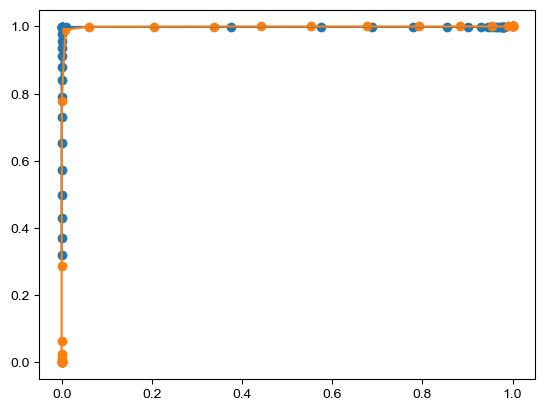

In [125]:
plt.scatter(fpr_list, tpr_list)
plt.plot(fpr_list, tpr_list)
plt.scatter(fpr_ndwi_list, tpr_ndwi_list)
plt.plot(fpr_ndwi_list, tpr_ndwi_list)

In [ ]:
TP = 1318523
FP = 787693
TN = 1682943
FN = 104
[-0.5, 0, 0.5]
TPR 0.9999211300845501
FPR 0.31882195515648604
acc: 0.7920975662021876